In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
!pip install tensorflow

In [4]:
# ============================================================
# Cell 1.1: Import Library
# ============================================================
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import datasets, utils, layers, models, optimizers, regularizers
from IPython.display import display


print("Python     :", sys.version.split()[0])
print("TensorFlow :", tf.__version__)
print("NumPy      :", np.__version__)
print("Matplotlib :", matplotlib.__version__)
print("GPU        :", tf.config.list_physical_devices("GPU"))


SEED          = 42
NUM_CLASSES   = 10
LEARNING_RATE = 0.0005
BATCH_SIZE    = 32
EPOCHS        = 10
VAL_SPLIT     = 0.1

tf.keras.utils.set_random_seed(SEED)


OUTPUT_DIR = "/content/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def save_fig(fig, filename):
    fig.savefig(os.path.join(OUTPUT_DIR, filename), dpi=150, bbox_inches="tight")

Python     : 3.12.13
TensorFlow : 2.20.0
NumPy      : 2.0.2
Matplotlib : 3.10.0
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Loading CIFAR-10 from Google Drive...
x_train: (50000, 32, 32, 3) uint8
y_train: (50000, 1) uint8
x_test : (10000, 32, 32, 3) uint8
y_test : (10000, 1) uint8
Pixel range: 0 -> 255
Number of images per layer (train): [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


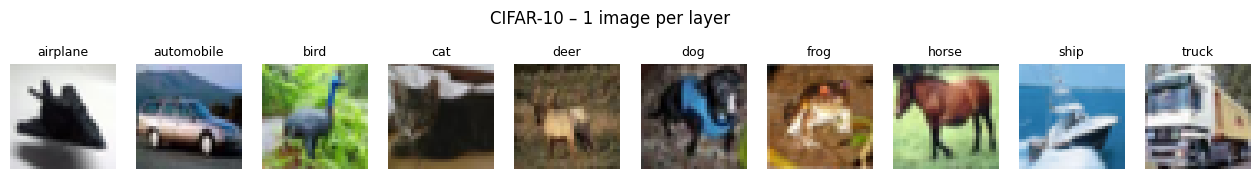

In [5]:
# ============================================================
# Cell 1.2 - Download / Load CIFAR-10 from Google Drive
# ============================================================
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import datasets

# Google Drive folder
DRIVE_DIR = "/content/drive/MyDrive/Trojan Study/Trojan Master/Fall 2026/CS-6615: Foundation of Generative Al/Assignment"

os.makedirs(DRIVE_DIR, exist_ok=True)

DATA_PATH = os.path.join(DRIVE_DIR, "cifar10_dataset.npz")

# ------------------------------------------------------------
# Load from Drive if dataset already exists
# Otherwise download and save it to Drive
# ------------------------------------------------------------
if os.path.exists(DATA_PATH):
    print("Loading CIFAR-10 from Google Drive...")

    data = np.load(DATA_PATH)

    x_train = data["x_train"]
    y_train = data["y_train"]
    x_test = data["x_test"]
    y_test = data["y_test"]

    data.close()

else:
    print("Downloading CIFAR-10...")

    (x_train, y_train), (x_test, y_test) = datasets.cifar10.load_data()

    print("Saving CIFAR-10 to Google Drive...")

    np.savez(
        DATA_PATH,
        x_train=x_train,
        y_train=y_train,
        x_test=x_test,
        y_test=y_test
    )

    print(f"Dataset saved to: {DATA_PATH}")


# ============================================================
# Dataset information
# ============================================================

CLASS_NAMES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("x_train:", x_train.shape, x_train.dtype)
print("y_train:", y_train.shape, y_train.dtype)
print("x_test :", x_test.shape, x_test.dtype)
print("y_test :", y_test.shape, y_test.dtype)
print("Pixel range:", x_train.min(), "->", x_train.max())
print(
    "Number of images per layer (train):",
    np.bincount(y_train.flatten())
)


# ============================================================
# Visualization
# ============================================================

fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(16, 2.2))

for c, ax in enumerate(axes):
    idx = np.where(y_train.flatten() == c)[0][0]
    ax.imshow(x_train[idx])
    ax.set_title(CLASS_NAMES[c], fontsize=9)
    ax.axis("off")

plt.suptitle("CIFAR-10 – 1 image per layer")

save_fig(fig, "01_image_per_class.png")
plt.show()

In [6]:
# ============================================================
# Cell 1.3 - Preprocess
# ============================================================

x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

# one-hot encode
y_train_int = y_train.flatten()
y_test_int  = y_test.flatten()
y_train = utils.to_categorical(y_train_int, NUM_CLASSES)
y_test  = utils.to_categorical(y_test_int, NUM_CLASSES)

print("x_train:", x_train.shape, x_train.dtype, "| range:", x_train.min(), "->", x_train.max())
print("y_train:", y_train.shape)
print(f"First Label: {y_train_int[0]} ({CLASS_NAMES[y_train_int[0]]}) ->", y_train[0])

x_train: (50000, 32, 32, 3) float32 | range: 0.0 -> 1.0
y_train: (50000, 10)
First Label: 6 (frog) -> [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


In [7]:
# ============================================================
# Cell 2.1 - MLP Function
# ============================================================
def build_mlp(hidden_units=(200, 150),
              activation="relu",
              output_activation="softmax",
              dropout=0.0,
              l2=0.0,
              name="mlp"):

    reg = regularizers.l2(l2) if l2 > 0 else None

    model = models.Sequential(name=name)
    model.add(layers.Input(shape=(32, 32, 3)))
    model.add(layers.Flatten(name="flatten"))

    for i, units in enumerate(hidden_units, start=1):
        if activation == "leaky_relu":
            model.add(layers.Dense(units, kernel_regularizer=reg, name=f"dense_{i}"))
            model.add(layers.LeakyReLU(name=f"leaky_relu_{i}"))
        else:
            model.add(layers.Dense(units, activation=activation,
                                   kernel_regularizer=reg, name=f"dense_{i}"))
        if dropout > 0:
            model.add(layers.Dropout(dropout, name=f"dropout_{i}"))

    # Output: 10 units
    model.add(layers.Dense(NUM_CLASSES, activation=output_activation, name="output"))
    return model

In [8]:
# ============================================================
# Cell 2.2 - Baseline model
# ============================================================
model = build_mlp(name="baseline_mlp")
model.summary()

Model: "baseline_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 200)            │       614,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 150)            │        30,150 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 646,260 (2.47 MB)

 Trainable params: 646,260 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# ============================================================
# Cell 2.3 - check parameter count
# ============================================================
def dense_params(n_in, n_units):
    return n_in * n_units + n_units

layers_info = [("dense_1", 3072, 200), ("dense_2", 200, 150), ("output", 150, NUM_CLASSES)]
total = 0
for name, n_in, n_units in layers_info:
    p = dense_params(n_in, n_units)
    total += p

    print(f"{name:<8}: {n_in} x {n_units} + {n_units} = {p:,}")
print(f"Total : {total:,}")
print(f"Keras count     : {model.count_params():,}")

dense_1 : 3072 x 200 + 200 = 614,600
dense_2 : 200 x 150 + 150 = 30,150
output  : 150 x 10 + 10 = 1,510
Total : 646,260
Keras count     : 646,260


In [10]:
# ============================================================
# Cell 3.1 - Compile
# ============================================================
model.compile(
    optimizer=optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
print("Optimizer:", type(model.optimizer).__name__, "| lr =", LEARNING_RATE)

Optimizer: Adam | lr = 0.0005


In [11]:
# ============================================================
# Cell 3.2 - CCE manual vs Keras (model not trained)
# ============================================================
y_true_demo = y_train[:5]
y_pred_demo = model.predict(x_train[:5], verbose=0)

# Manual: L = -sum(y * log(p));
manual_loss = -np.sum(y_true_demo * np.log(y_pred_demo + 1e-7), axis=1)
keras_loss  = tf.keras.losses.categorical_crossentropy(y_true_demo, y_pred_demo).numpy()

print("Softmax image 0:", np.round(y_pred_demo[0], 3), "| Sum =", round(float(y_pred_demo[0].sum()), 4))
print("Loss manual:", np.round(manual_loss, 4))
print("Loss Keras   :", np.round(keras_loss, 4))
print("ln(10)       :", round(float(np.log(10)), 4))

Softmax image 0: [0.124 0.161 0.103 0.073 0.101 0.128 0.094 0.092 0.079 0.045] | Sum = 1.0
Loss manual: [2.3656 3.2843 3.4525 2.1749 2.2308]
Loss Keras   : [2.3656 3.2843 3.4525 2.1749 2.2308]
ln(10)       : 2.3026


In [12]:
# ============================================================
# Cell 4.1 - Train baseline + Checkpoint
# ============================================================
import os
import time
from tensorflow.keras.callbacks import ModelCheckpoint

# Google Drive folder
CHECKPOINT_DIR = "/content/drive/MyDrive/Trojan Study/Trojan Master/Fall 2026/CS-6615: Foundation of Generative Al/Assignment"

# Create folder if it doesn't exist
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Save the best model based on validation loss
checkpoint_path = os.path.join(CHECKPOINT_DIR, "baselineModel_best.keras")

checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

start = time.time()

history = model.fit(
    x_train,
    y_train,
    batch_size=BATCH_SIZE,      # 32
    epochs=EPOCHS,              # 10
    shuffle=True,
    validation_split=VAL_SPLIT,
    callbacks=[checkpoint],
    verbose=1,
)

print(f"Time train: {time.time() - start:.1f}s")
print(f"Best model saved to: {checkpoint_path}")

Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2770 - loss: 1.9832
Epoch 1: val_loss improved from None to 1.75308, saving model to /content/drive/MyDrive/Trojan Study/Trojan Master/Fall 2026/CS-6615: Foundation of Generative Al/Assignment/baselineModel_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Trojan Study/Trojan Master/Fall 2026/CS-6615: Foundation of Generative Al/Assignment/baselineModel_best.keras
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.3271 - loss: 1.8643 - val_accuracy: 0.3848 - val_loss: 1.7531
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3888 - loss: 1.7068
Epoch 2: val_loss improved from 1.75308 to 1.67408, saving model to /content/drive/MyDrive/Trojan Study/Trojan Master/Fall 2026/CS-6615: Foundation of Generative Al/Assignment/baselineModel_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Trojan Study/Trojan Master/Fall 2026/CS-6615: Foundation of Generative Al/Assign

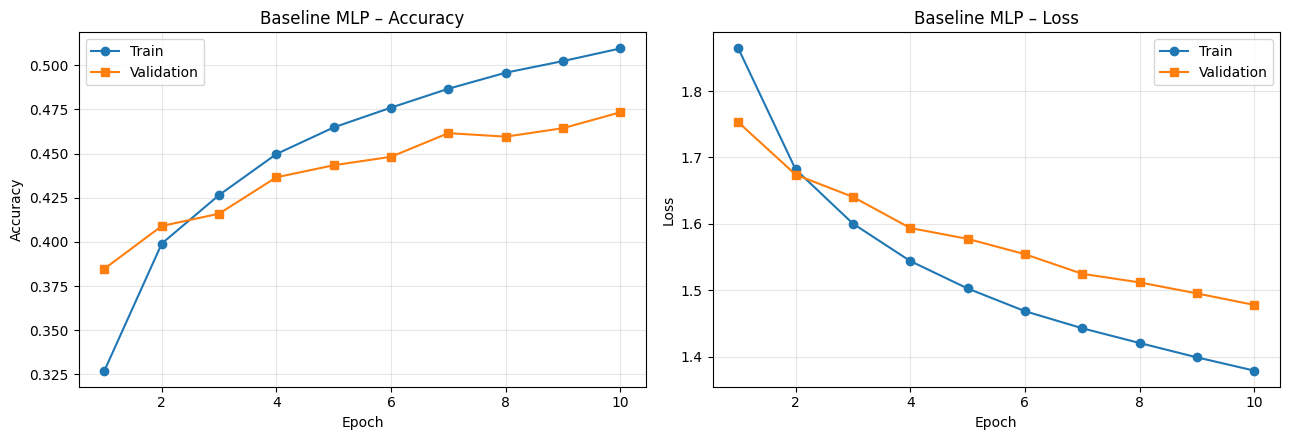

Epoch final - train acc: 0.5096 | val acc: 0.4734
Epoch final - train loss: 1.3788 | val loss: 1.4778


In [13]:
# ============================================================
# Cell 4.2 - training/validation curves
# ============================================================
def plot_history(history, title, filename=None):
    h = history.history
    ep = range(1, len(h["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    axes[0].plot(ep, h["accuracy"], "o-", label="Train")
    axes[0].plot(ep, h["val_accuracy"], "s-", label="Validation")
    axes[0].set(title=f"{title} – Accuracy", xlabel="Epoch", ylabel="Accuracy")

    axes[1].plot(ep, h["loss"], "o-", label="Train")
    axes[1].plot(ep, h["val_loss"], "s-", label="Validation")
    axes[1].set(title=f"{title} – Loss", xlabel="Epoch", ylabel="Loss")

    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    if filename:
        save_fig(fig, filename)
    plt.show()

plot_history(history, "Baseline MLP", "02_baseline_curves.png")

h = history.history
print(f"Epoch final - train acc: {h['accuracy'][-1]:.4f} | val acc: {h['val_accuracy'][-1]:.4f}")
print(f"Epoch final - train loss: {h['loss'][-1]:.4f} | val loss: {h['val_loss'][-1]:.4f}")

##  Evaluation và Visualization

In [14]:
# ============================================================
# Cell 5.1 - Evaluate on test set and compare with random guessing
# ============================================================
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
random_acc = 1 / NUM_CLASSES

print(f"Test loss      : {test_loss:.4f}")
print(f"Test accuracy  : {test_acc:.4f} ({test_acc * 100:.2f}%)")
print(f"Random guessing: {random_acc * 100:.1f}%")
print(f"=> better random {test_acc / random_acc:.1f} times")

Test loss      : 1.4640
Test accuracy  : 0.4795 (47.95%)
Random guessing: 10.0%
=> better random 4.8 times


In [15]:
# ============================================================
# Cell 5.2 - Predict -> argmax -> accuracy of each layer

# ============================================================
probs       = model.predict(x_test, verbose=0)   # (10000, 10)
pred_labels = np.argmax(probs, axis=1)            # (10000,) layer prediction
true_labels = np.argmax(y_test, axis=1)           # (10000,) layer realistic

print(f"Accuracy manual: {np.mean(pred_labels == true_labels):.4f} (fit as evaluate)\n")

print("Accuracy each layer:")
for c, name in enumerate(CLASS_NAMES):
    mask = true_labels == c
    print(f"  {name:<11}: {np.mean(pred_labels[mask] == c):.3f}")

Accuracy manual: 0.4795 (fit as evaluate)

Accuracy each layer:
  airplane   : 0.448
  automobile : 0.552
  bird       : 0.298
  cat        : 0.183
  deer       : 0.394
  dog        : 0.394
  frog       : 0.621
  horse      : 0.509
  ship       : 0.703
  truck      : 0.693


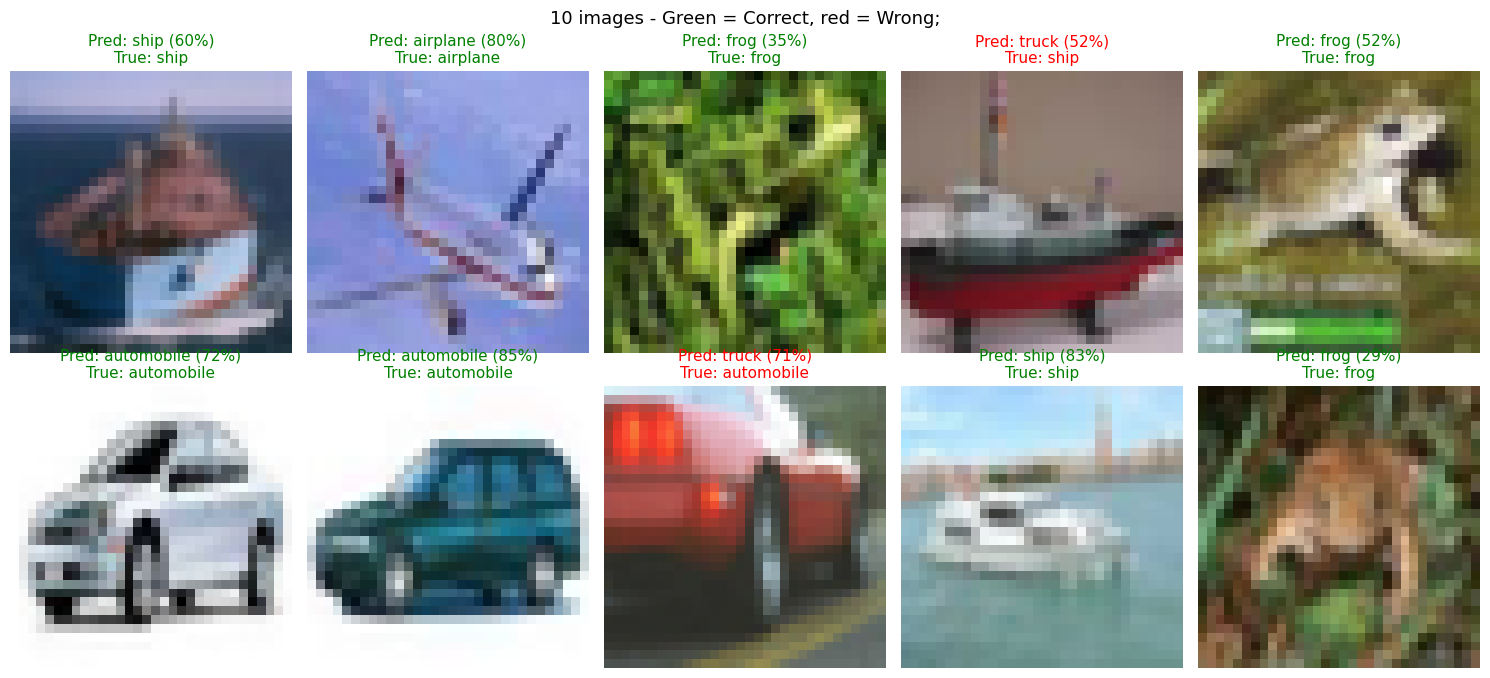

In [16]:
# ============================================================
# Cell 5.3
# Green = Correct, red = Wrong;
# ============================================================
rng = np.random.default_rng(SEED)
idx = rng.choice(len(x_test), size=10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for ax, i in zip(axes.flat, idx):
    p, t = pred_labels[i], true_labels[i]
    ax.imshow(x_test[i])
    ax.set_title(f"Pred: {CLASS_NAMES[p]} ({probs[i, p]:.0%})\nTrue: {CLASS_NAMES[t]}",
                 color="green" if p == t else "red", fontsize=11)
    ax.axis("off")
plt.suptitle("10 images - Green = Correct, red = Wrong;", fontsize=13)
plt.tight_layout()
save_fig(fig, "03_random_predictions.png")
plt.show()

## Impact of Hyperparameter, Regularization và Optimization

### Cell 6.0 – Run experience
Each experience: create new model , compile, train 10 epoch with batch 32, evaluate on test, save result .


In [17]:
# ============================================================
# Cell 6.0
# ============================================================
results = {}

def make_optimizer(name, lr):
    """Tạo optimizer mới cho mỗi model (optimizer không dùng chung giữa các model)."""
    if name == "adam":
        return optimizers.Adam(learning_rate=lr)
    if name == "rmsprop":
        return optimizers.RMSprop(learning_rate=lr)
    if name == "sgd":
        return optimizers.SGD(learning_rate=lr, momentum=0.9)
    raise ValueError(f"Unknown optimizer: {name}")

def run_experiment(name, optimizer="adam", lr=LEARNING_RATE, loss="categorical_crossentropy",
                   batch_size=BATCH_SIZE, epochs=EPOCHS, **model_kwargs):
    """Build -> compile -> fit -> evaluate -> lưu kết quả. model_kwargs truyền vào build_mlp."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    m = build_mlp(name="exp", **model_kwargs)
    m.compile(optimizer=make_optimizer(optimizer, lr), loss=loss,
              metrics=[tf.keras.metrics.CategoricalAccuracy(name="accuracy")])

    start = time.time()
    hist = m.fit(x_train, y_train, batch_size=batch_size, epochs=epochs,
                 shuffle=True, validation_split=VAL_SPLIT, verbose=0)
    duration = time.time() - start
    _, t_acc = m.evaluate(x_test, y_test, verbose=0)

    h = hist.history
    results[name] = {
        "params": m.count_params(),
        "train_acc": h["accuracy"][-1],
        "val_acc": h["val_accuracy"][-1],
        "best_val_acc": max(h["val_accuracy"]),
        "test_acc": t_acc,
        "gap(train-val)": h["accuracy"][-1] - h["val_accuracy"][-1],
        "time_s": duration,
        "history": h,
    }
    print(f"{name:<22} | test={t_acc:.4f} | train={h['accuracy'][-1]:.4f} | "
          f"val={h['val_accuracy'][-1]:.4f} | gap={h['accuracy'][-1] - h['val_accuracy'][-1]:+.4f} | {duration:.0f}s")
    return m

def plot_compare(names, title, filename=None):
    """left: accuracy (solid = val, dotted = train). right: validation loss."""
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    for i, name in enumerate(names):
        h = results[name]["history"]
        ep = range(1, len(h["loss"]) + 1)
        color = f"C{i}"
        axes[0].plot(ep, h["val_accuracy"], "-o", color=color, markersize=4, label=name)
        axes[0].plot(ep, h["accuracy"], "--", color=color, alpha=0.5)
        axes[1].plot(ep, h["val_loss"], "-o", color=color, markersize=4, label=name)
    axes[0].set(title=f"{title} – Accuracy (solid = val, dotted = train)", xlabel="Epoch", ylabel="Accuracy")
    axes[1].set(title=f"{title} – Validation loss", xlabel="Epoch", ylabel="Loss")
    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    plt.tight_layout()
    if filename:
        save_fig(fig, filename)
    plt.show()

baseline               | test=0.4795 | train=0.5096 | val=0.4734 | gap=+0.0362 | 48s
narrow_100-50          | test=0.4473 | train=0.4668 | val=0.4444 | gap=+0.0224 | 47s
wide_512-256           | test=0.4744 | train=0.5292 | val=0.4818 | gap=+0.0474 | 48s
1layer_200             | test=0.4551 | train=0.4835 | val=0.4540 | gap=+0.0295 | 45s
3layers_512-256-128    | test=0.4783 | train=0.5376 | val=0.4622 | gap=+0.0754 | 51s
leaky_relu             | test=0.4636 | train=0.5211 | val=0.4630 | gap=+0.0581 | 48s
tanh                   | test=0.4226 | train=0.4467 | val=0.4194 | gap=+0.0273 | 48s


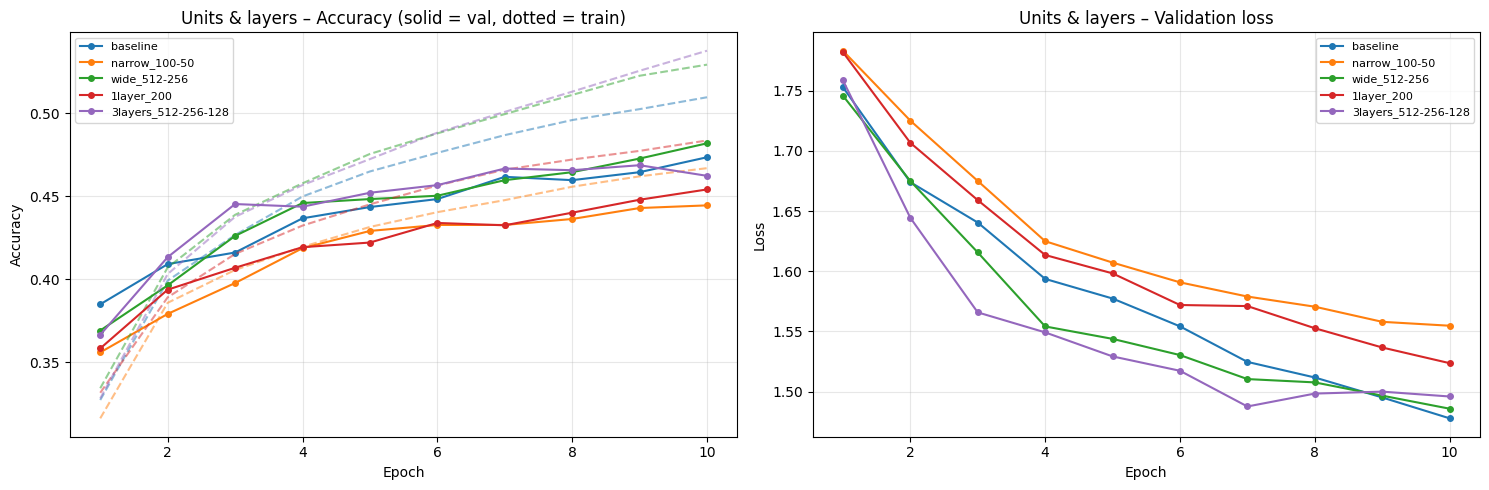

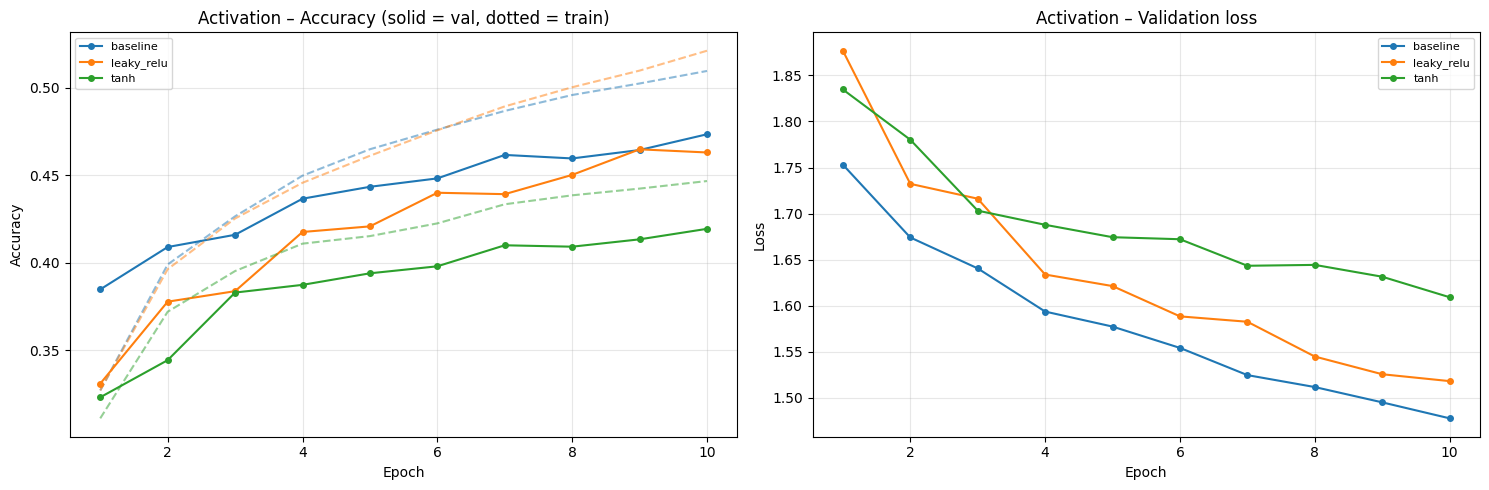

In [18]:
# ============================================================
# Cell 6.1 - Hyperparameter experiments
# ============================================================
hp_experiments = {
    "baseline":          dict(hidden_units=(200, 150), activation="relu"),
    "narrow_100-50":     dict(hidden_units=(100, 50)),
    "wide_512-256":      dict(hidden_units=(512, 256)),
    "1layer_200":        dict(hidden_units=(200,)),
    "3layers_512-256-128": dict(hidden_units=(512, 256, 128)),
    "leaky_relu":        dict(activation="leaky_relu"),
    "tanh":              dict(activation="tanh"),
}
for name, kw in hp_experiments.items():
    run_experiment(name, **kw)

plot_compare(["baseline", "narrow_100-50", "wide_512-256", "1layer_200", "3layers_512-256-128"],
             "Units & layers", "04_hp_units_layers.png")
plot_compare(["baseline", "leaky_relu", "tanh"], "Activation", "05_hp_activation.png")

wide+dropout0.2        | test=0.4474 | train=0.4253 | val=0.4448 | gap=-0.0195 | 60s
wide+dropout0.5        | test=0.2976 | train=0.2670 | val=0.2994 | gap=-0.0324 | 51s
wide+L2_1e-4           | test=0.4652 | train=0.5202 | val=0.4730 | gap=+0.0472 | 55s
wide+L2_1e-3           | test=0.4641 | train=0.4858 | val=0.4652 | gap=+0.0206 | 49s
wide+dropout0.2+L2     | test=0.4457 | train=0.4192 | val=0.4446 | gap=-0.0254 | 52s


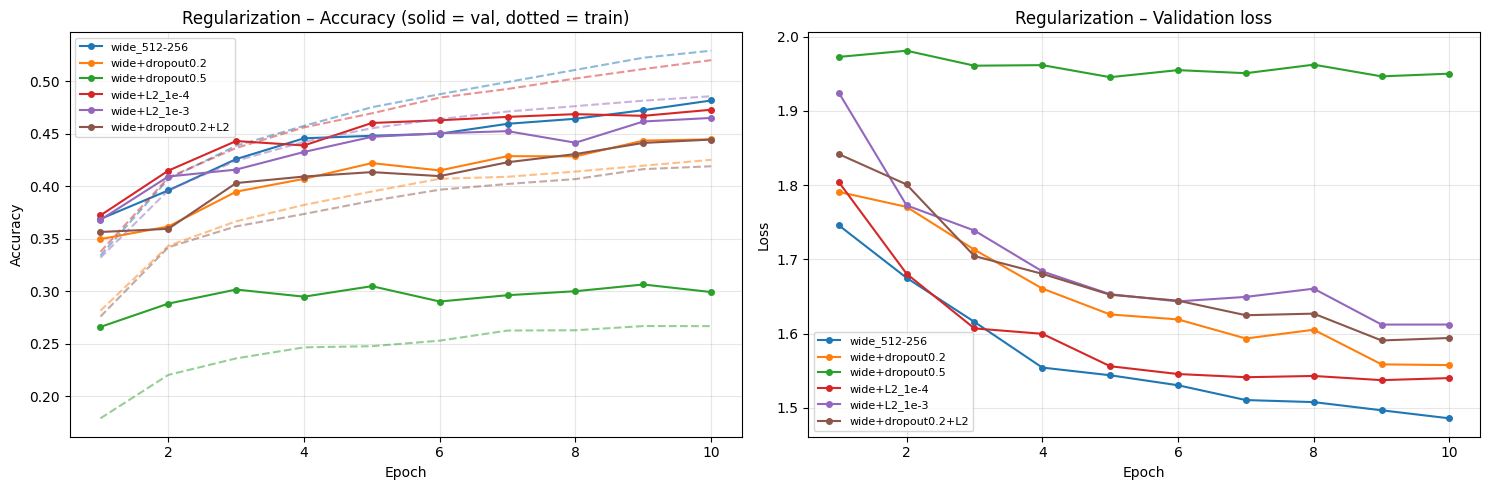

In [19]:
# ============================================================
# Cell 6.2 - Regularization experiments (on wide 512-256)
# ============================================================
WIDE = (512, 256)
reg_experiments = {
    "wide+dropout0.2":      dict(hidden_units=WIDE, dropout=0.2),
    "wide+dropout0.5":      dict(hidden_units=WIDE, dropout=0.5),
    "wide+L2_1e-4":         dict(hidden_units=WIDE, l2=1e-4),
    "wide+L2_1e-3":         dict(hidden_units=WIDE, l2=1e-3),
    "wide+dropout0.2+L2":   dict(hidden_units=WIDE, dropout=0.2, l2=1e-4),
}
for name, kw in reg_experiments.items():
    run_experiment(name, **kw)

plot_compare(["wide_512-256"] + list(reg_experiments), "Regularization", "06_regularization.png")

rmsprop                | test=0.4300 | train=0.5027 | val=0.4318 | gap=+0.0709 | 45s


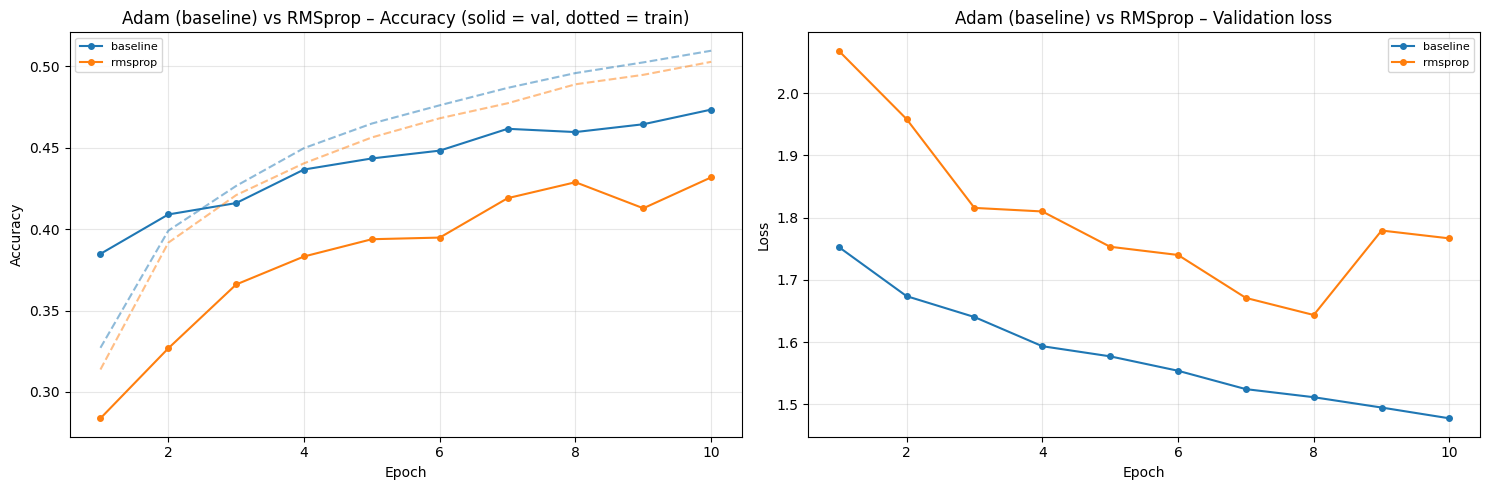

In [20]:
# ============================================================
# Cell 6.3 - Optimizer comparison
# ============================================================
run_experiment("rmsprop", optimizer="rmsprop")


plot_compare(["baseline", "rmsprop"], "Adam (baseline) vs RMSprop", "07_optimizer.png")

out_linear_logits      | test=0.4795 | train=0.5096 | val=0.4734 | gap=+0.0362 | 47s
out_sigmoid_bce        | test=0.4727 | train=0.5200 | val=0.4678 | gap=+0.0522 | 49s
out_softmax_mse        | test=0.4600 | train=0.5036 | val=0.4534 | gap=+0.0502 | 46s


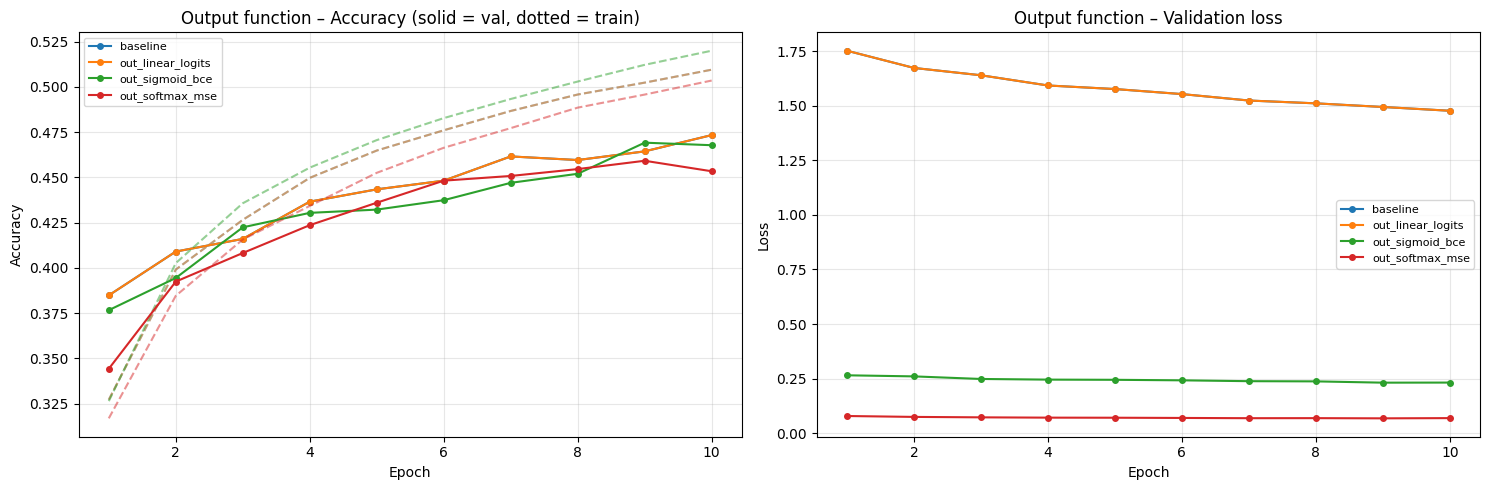

In [21]:
# ============================================================
# Cell 6.4 - Output function experiments
# ============================================================
run_experiment("out_linear_logits", output_activation="linear",
               loss=tf.keras.losses.CategoricalCrossentropy(from_logits=True))
run_experiment("out_sigmoid_bce", output_activation="sigmoid", loss="binary_crossentropy")
run_experiment("out_softmax_mse", output_activation="softmax", loss="mse")

plot_compare(["baseline", "out_linear_logits", "out_sigmoid_bce", "out_softmax_mse"],
             "Output function", "08_output_function.png")

### Cell 6.5 – Batch size và learning rate


lr_0.0001              | test=0.4672 | train=0.5135 | val=0.4652 | gap=+0.0483 | 46s
lr_0.005               | test=0.3558 | train=0.3666 | val=0.3592 | gap=+0.0074 | 47s
batch_128              | test=0.4752 | train=0.5060 | val=0.4816 | gap=+0.0244 | 18s
batch_512              | test=0.4700 | train=0.4860 | val=0.4648 | gap=+0.0212 | 12s


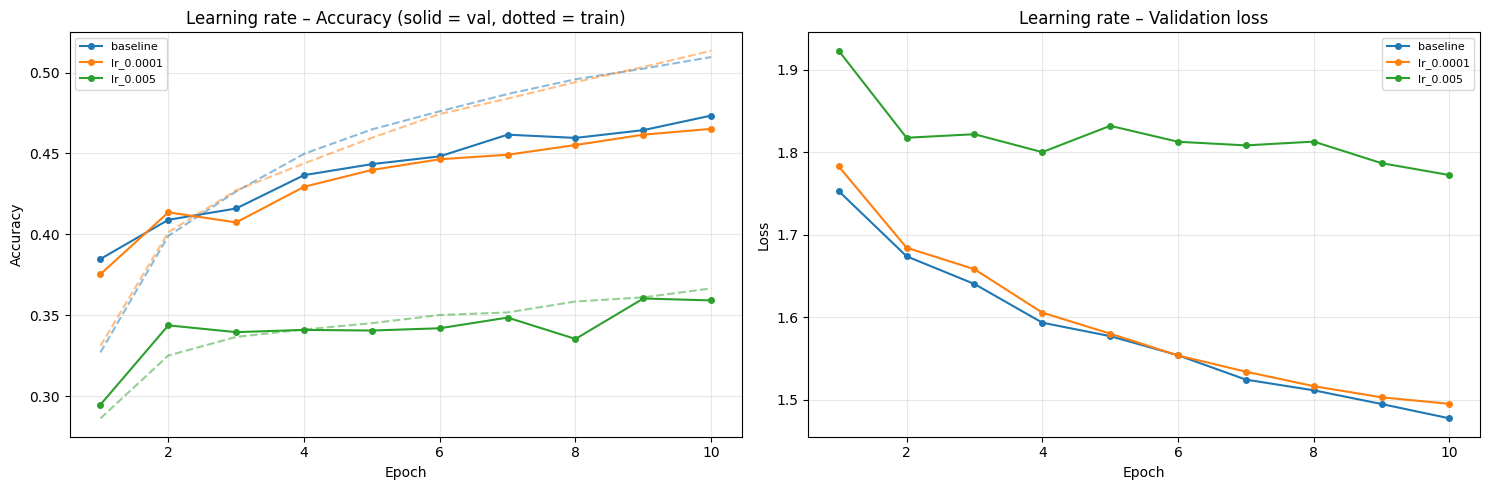

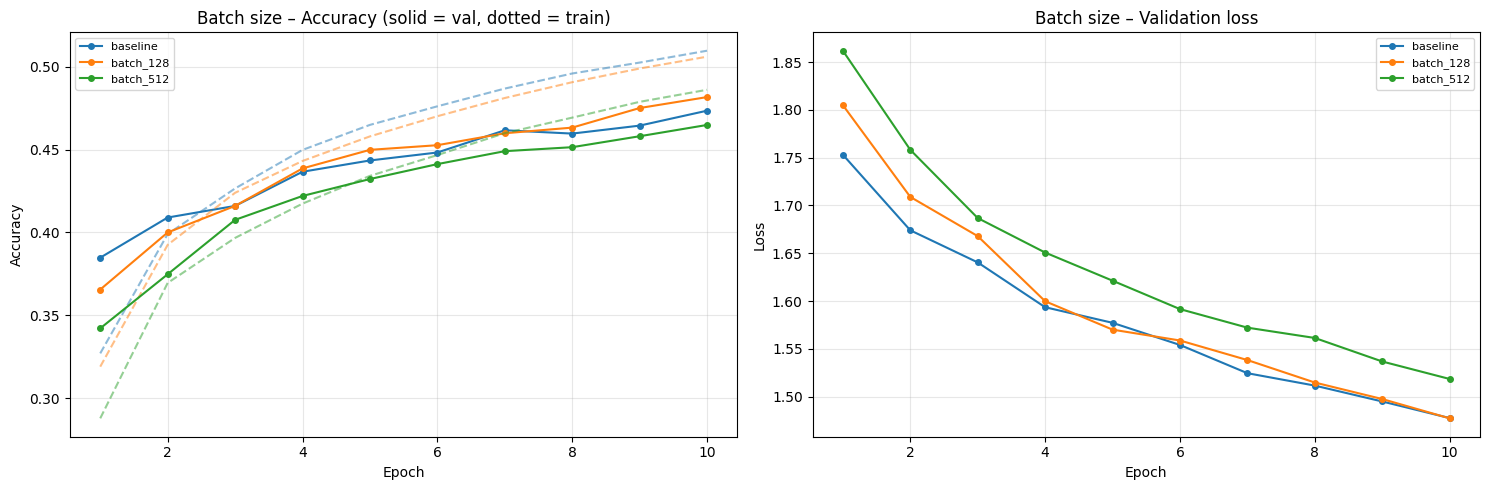

In [22]:
# ============================================================
# Cell 6.5 - Batch size & learning rate experiments
# ============================================================
run_experiment("lr_0.0001", lr=0.0001)
run_experiment("lr_0.005",  lr=0.005)
run_experiment("batch_128", batch_size=128)
run_experiment("batch_512", batch_size=512)

plot_compare(["baseline", "lr_0.0001", "lr_0.005"], "Learning rate", "09_learning_rate.png")
plot_compare(["baseline", "batch_128", "batch_512"], "Batch size", "10_batch_size.png")

### Cell 6.6 – Summary


,params,train_acc,val_acc,best_val_acc,test_acc,gap(train-val),time_s
experiment,,,,,,,
baseline,646260,0.5096,0.4734,0.4734,0.4795,0.0362,47.7
narrow_100-50,312860,0.4668,0.4444,0.4444,0.4473,0.0224,47.3
wide_512-256,1707274,0.5292,0.4818,0.4818,0.4744,0.0474,47.9
1layer_200,616610,0.4835,0.4540,0.4540,0.4551,0.0295,45.4
3layers_512-256-128,1738890,0.5376,0.4622,0.4686,0.4783,0.0754,50.9
leaky_relu,646260,0.5211,0.4630,0.4648,0.4636,0.0581,47.6
tanh,646260,0.4467,0.4194,0.4194,0.4226,0.0273,47.6
wide+dropout0.2,1707274,0.4253,0.4448,0.4448,0.4474,-0.0195,60.0
wide+dropout0.5,1707274,0.2670,0.2994,0.3066,0.2976,-0.0324,50.8


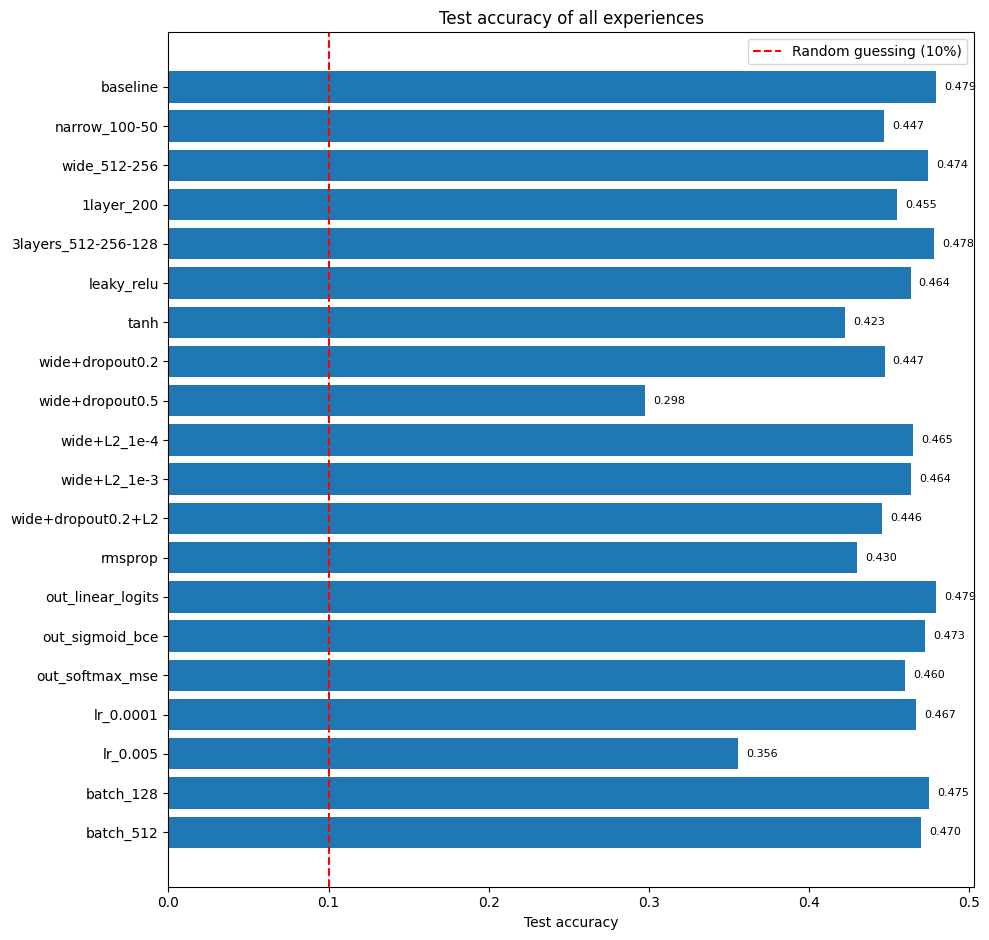

In [25]:
# ============================================================
# Cell 6.6 - Summary and Graph
# ============================================================
summary = pd.DataFrame(
    [{"experiment": n, **{k: v for k, v in r.items() if k != "history"}} for n, r in results.items()]
).set_index("experiment")
summary = summary.round({"train_acc": 4, "val_acc": 4, "best_val_acc": 4,
                         "test_acc": 4, "gap(train-val)": 4, "time_s": 1})
display(summary)
summary.to_csv(os.path.join(OUTPUT_DIR, "results_summary.csv"))

fig, ax = plt.subplots(figsize=(10, 0.4 * len(summary) + 1.5))
ax.barh(summary.index, summary["test_acc"], color="C0")
ax.axvline(0.1, color="red", linestyle="--", label="Random guessing (10%)")
for y, v in enumerate(summary["test_acc"]):
    ax.text(v + 0.005, y, f"{v:.3f}", va="center", fontsize=8)
ax.set(xlabel="Test accuracy", title="Test accuracy of all experiences")
ax.invert_yaxis()
ax.legend()
plt.tight_layout()
save_fig(fig, "11_test_accuracy_summary.png")
plt.show()

In [24]:
# ============================================================
# Cell 7 - Zip và save outputs vào Google Drive
# ============================================================
import os
import shutil

# Google Drive folder
DRIVE_DIR = "/content/drive/MyDrive/Trojan Study/Trojan Master/Fall 2026/CS-6615: Foundation of Generative Al/Assignment"

# Make sure folder exists
os.makedirs(DRIVE_DIR, exist_ok=True)

# Show output files
print(" file saved:", sorted(os.listdir(OUTPUT_DIR)))

# Create ZIP directly in Google Drive
zip_path = os.path.join(DRIVE_DIR, "cifar10_mlp_outputs")

zip_file = shutil.make_archive(
    zip_path,
    "zip",
    OUTPUT_DIR
)

print(f"\nZIP file saved to Trojan Study/Trojan Master/Fall 2026/CS-6615: Foundation of Generative Al/Assignment:")
print(zip_file)

 file saved: ['01_image_per_class.png', '02_baseline_curves.png', '03_random_predictions.png', '04_hp_units_layers.png', '05_hp_activation.png', '06_regularization.png', '07_optimizer.png', '08_output_function.png', '09_learning_rate.png', '10_batch_size.png', '11_test_accuracy_summary.png', 'results_summary.csv']

ZIP file saved to Trojan Study/Trojan Master/Fall 2026/CS-6615: Foundation of Generative Al/Assignment:
/content/drive/MyDrive/Trojan Study/Trojan Master/Fall 2026/CS-6615: Foundation of Generative Al/Assignment/cifar10_mlp_outputs.zip


In [26]:
# ============================================================
# Cell 8 - Download final result
# ============================================================
from google.colab import files
import shutil
import os

DOWNLOAD_PATH = "/content/hw_result_HongTon.zip"

shutil.copy(
    "/content/drive/MyDrive/Trojan Study/Trojan Master/Fall 2026/CS-6615: Foundation of Generative Al/Assignment/cifar10_mlp_outputs.zip",
    DOWNLOAD_PATH
)

files.download(DOWNLOAD_PATH)

print("Downloaded:", DOWNLOAD_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: /content/hw_result_HongTon.zip
